# 01 EDA: 上位解法で効いていた要素の検証

## 目的
上位解法（1〜15位、19位）で「目的変数（J）の予測に効いていた」とされる要素が、データ上でどれだけ J を説明しているかを確認する。
**ここでは上位解法で使われていた要素だけを対象にする。** 新しい特徴量は考えない。

## 上位解法から抽出した仮説

| # | 要素 | 使っていた上位チーム | このノートで確認すること |
|---|---|---|---|
| H1 | coupling type と**サブタイプ**（結合相手の原子の結合数＝混成） | 全チーム。1位は33サブタイプ、7位と13位は type 別モデル | type 別の分布とスケール、サブタイプで値が分かれるか |
| H2 | ペア原子間の**距離** | 全チーム。9位は距離と原子種だけで -2.97 | 距離と J の関係 |
| H3 | 2J の**結合角** | 4・6・7・10・14位（7位は「key」と明言） | 角度と J の関係 |
| H4 | 3J の**二面角**（Karplus） | 4・6・7・10・13・14位（1位では四つ組の二面角が汎化を悪化させた） | 二面角と J の関係 |
| H5 | **経路上の原子**（中間原子の元素・結合数） | 7位（中間原子への距離）、1位（階層的な型埋め込み） | 中間原子による違い |
| H6 | **結合の種類**（単・二重・三重・芳香族） | 1・4・8・14位（RDKit / OpenBabel） | 結合次数による違い（RDKit で一部の分子を確認） |
| H7 | 原子の**電荷**（Mulliken / 部分電荷） | 1位（OpenBabel）、4位（QM9 の Mulliken）、10位、12位（事前学習）、14位（補助予測）、19位 | 電荷が残りの誤差を説明するか |
| H8 | 補助ターゲット **fc / sd / pso / dso** | 3位（大きく効いた）、6・10・14位。2位では効かず | 成分と J の関係 |
| H9 | 補助ターゲット **遮蔽テンソル**（固有値） | 14位 | 遮蔽が残りの誤差を説明するか |
| H10 | **対称性**（HH ペアの入れ替え、3J の複数経路） | 2・4・7位 | HH ペアの並び、複数経路の頻度 |
| H11 | 目的変数の**変換・損失**（type 別の標準化、type 別 log-MAE） | 2・4・8位 | type 別のスケール差 |

対象外にした要素:
- **原子の物性値**（4位の電気陰性度など）: 元素ごとの定数なので、情報は原子種と同じ
- **生の xyz**（2位・3位）: 特徴量ではなくモデルへの入力の形

## 効き具合の測り方（モデルを使わない）
分子単位で train を 80% / 20% に分け、80% 側で「type × 特徴量のビン」ごとの**中央値**を求め、20% 側をその中央値で予測する。
このときの **type 別 log(MAE)** を比べる。指標が MAE なので、予測値は平均ではなく中央値にする。
ビンを増やすと過学習しうるので、未知のグループは type の中央値で代用する。

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('../archive')
FIG = Path('figs')
FIG.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)
pd.set_option('display.float_format', lambda v: f'{v:.4g}')
plt.rcParams.update({'figure.dpi': 80, 'axes.grid': True, 'grid.alpha': 0.3})
# 図の日本語表示用（macOS のヒラギノ。なければ既定のフォント）
from matplotlib import font_manager
if any(f.name == 'Hiragino Sans' for f in font_manager.fontManager.ttflist):
    plt.rcParams['font.family'] = ['Hiragino Sans', 'DejaVu Sans']

TYPES = ['1JHC', '1JHN', '2JHC', '2JHH', '2JHN', '3JHC', '3JHH', '3JHN']
ELEM = np.array(['H', 'C', 'N', 'O', 'F'])
RNG = np.random.default_rng(0)


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', bbox_inches='tight')
    plt.show()

## 0. データの読み込み

In [2]:
t0 = time.time()
st = pd.read_csv(DATA / 'structures.csv',
                 dtype={'atom_index': np.int8, 'x': np.float32, 'y': np.float32, 'z': np.float32})
tr = pd.read_csv(DATA / 'train.csv',
                 dtype={'atom_index_0': np.int8, 'atom_index_1': np.int8, 'scalar_coupling_constant': np.float32})
te = pd.read_csv(DATA / 'test.csv', dtype={'atom_index_0': np.int8, 'atom_index_1': np.int8})
ct = pd.read_csv(DATA / 'scalar_coupling_contributions.csv', usecols=['fc', 'sd', 'pso', 'dso'], dtype=np.float32)
mu_path = DATA / 'mulliken_charges.csv'
if mu_path.is_dir():
    mu_path = mu_path / 'mulliken_charges.csv'
mu = pd.read_csv(mu_path, dtype={'atom_index': np.int8, 'mulliken_charge': np.float32})
ms = pd.read_csv(DATA / 'magnetic_shielding_tensors.csv', usecols=['molecule_name', 'atom_index', 'XX', 'YY', 'ZZ'],
                 dtype={'atom_index': np.int8, 'XX': np.float32, 'YY': np.float32, 'ZZ': np.float32})

tr = tr.rename(columns={'scalar_coupling_constant': 'J'})
# contributions は train.csv と同じ行順（4成分の和 = J で確認）
assert np.abs(ct.sum(axis=1).values - tr.J.values).max() < 0.01
tr = pd.concat([tr, ct], axis=1)
for df in (tr, te):
    df['type'] = pd.Categorical(df['type'], categories=TYPES)
print(f'loaded in {time.time() - t0:.0f}s', tr.shape, te.shape, st.shape)
tr.head()

loaded in 25s (4658147, 10) (2505542, 5) (2358657, 6)


,id,molecule_name,atom_index_0,atom_index_1,type,J,fc,sd,pso,dso
0,0,dsgdb9nsd_000001,1,0,1JHC,84.81,83.02,0.2546,1.259,0.272
1,1,dsgdb9nsd_000001,1,2,2JHH,-11.26,-11.03,0.353,2.858,-3.434
2,2,dsgdb9nsd_000001,1,3,2JHH,-11.25,-11.03,0.3529,2.859,-3.434
3,3,dsgdb9nsd_000001,1,4,2JHH,-11.25,-11.03,0.3529,2.859,-3.434
4,4,dsgdb9nsd_000001,2,0,1JHC,84.81,83.02,0.2546,1.259,0.272


分子を整数 ID にして、原子を「分子 × 最大29原子」の配列に詰める。以降の幾何計算はこの配列で行う。

In [3]:
mol_index = pd.Index(st.molecule_name.unique())
st['m'] = mol_index.get_indexer(st.molecule_name)
for df in (tr, te, mu, ms):
    df['m'] = mol_index.get_indexer(df.molecule_name)

M, MAXA = len(mol_index), 29
Z = np.full((M, MAXA), -1, np.int8)
XYZ = np.zeros((M, MAXA, 3), np.float32)
Z[st.m, st.atom_index] = st.atom.map({e: i for i, e in enumerate(ELEM)}).values
XYZ[st.m, st.atom_index] = st[['x', 'y', 'z']].values
NA = (Z >= 0).sum(1)

MUL = np.full((M, MAXA), np.nan, np.float32)
MUL[mu.m, mu.atom_index] = mu.mulliken_charge.values
SHI = np.full((M, MAXA), np.nan, np.float32)  # 等方遮蔽 = テンソルの対角平均（回転に依存しない）
SHI[ms.m, ms.atom_index] = ms[['XX', 'YY', 'ZZ']].mean(axis=1).values
# メモリ節約: 文字列の分子名と元の表はもう使わない
tr = tr.drop(columns=['molecule_name'])
te = te[['m', 'type']]
del st, mu, ms, ct
print('molecules', M, 'max atoms', NA.max())

molecules 130775 max atoms 29


## 1. 目的変数の概観（H1, H11）

In [4]:
g = tr.groupby('type', observed=True).J
summary = pd.DataFrame({
    'train_rows': g.size(),
    'test_rows': te.groupby('type', observed=True).size(),
    'mean': g.mean(), 'std': g.std(), 'min': g.min(), 'median': g.median(), 'max': g.max(),
    'MAE(median)': g.apply(lambda s: (s - s.median()).abs().mean()),
})
summary['log(MAE)'] = np.log(summary['MAE(median)'])
summary['test_share'] = summary.test_rows / summary.test_rows.sum()
print('type 別に中央値を返すだけの予測のスコア:', round(summary['log(MAE)'].mean(), 4))
summary

type 別に中央値を返すだけの予測のスコア: 1.1845


,train_rows,test_rows,mean,std,min,median,max,MAE(median),log(MAE),test_share
type,,,,,,,,,,
1JHC,709416,380609,94.98,18.28,66.6,88.22,204.9,11.29,2.424,0.1519
1JHN,43363,24195,47.48,10.92,24.32,47.79,80.42,9.73,2.275,0.009657
2JHC,1140674,613138,-0.2706,4.524,-36.22,-0.9491,42.82,2.63,0.9671,0.2447
2JHH,378036,203126,-10.29,3.98,-35.18,-11.33,11.85,2.426,0.8864,0.08107
2JHN,119253,64424,3.125,3.673,-2.621,2.019,17.74,2.862,1.052,0.02571
3JHC,1510379,811999,3.688,3.071,-18.58,2.88,76.04,2.421,0.8843,0.3241
3JHH,590611,317435,4.771,3.705,-3.02,3.691,17.48,2.947,1.081,0.1267
3JHN,166415,90616,0.9907,1.315,-3.172,0.6588,10.97,0.9112,-0.09298,0.03617


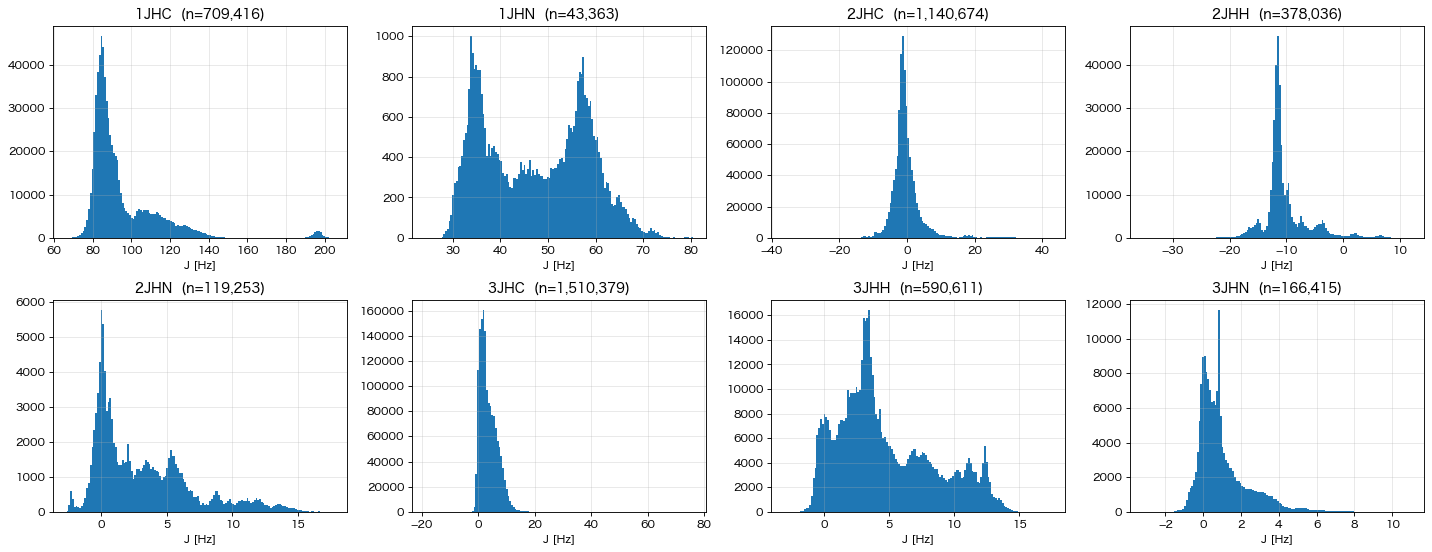

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, t in zip(axes.flat, TYPES):
    v = tr.J[tr.type == t]
    ax.hist(v, bins=150, color='C0')
    ax.set_title(f'{t}  (n={len(v):,})')
    ax.set_xlabel('J [Hz]')
savefig('01_target_hist')

**見どころ**: type ごとにスケールがまったく違う（1JHC は平均約95・標準偏差約18、3JHN は約1・1.3）。
type 別に標準化したり、type 別に損失を平均したりする（H11）のは、このスケール差を吸収するため。
分布が多峰になっている type は、サブタイプ（H1）が混ざっていることを示唆している。

### train と test の分布の比較（CV 設計の確認）

train と test の両方にある分子: 0


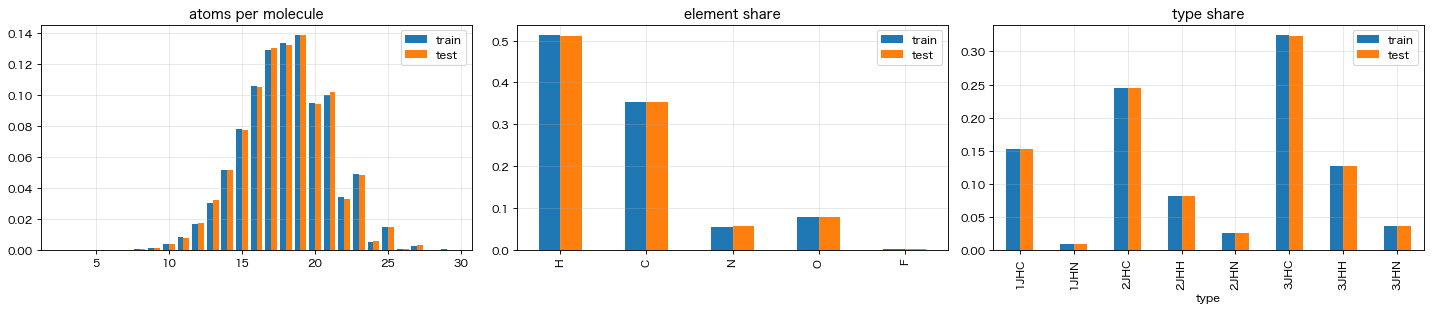

In [6]:
mol_tr = np.unique(tr.m.values)
mol_te = np.unique(te.m.values)
print('train と test の両方にある分子:', len(np.intersect1d(mol_tr, mol_te)))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].hist([NA[mol_tr], NA[mol_te]], bins=np.arange(2.5, 30), density=True, label=['train', 'test'])
axes[0].set_title('atoms per molecule')
axes[0].legend()
comp = pd.DataFrame({
    'train': [(Z[mol_tr] == i).sum() / (Z[mol_tr] >= 0).sum() for i in range(5)],
    'test': [(Z[mol_te] == i).sum() / (Z[mol_te] >= 0).sum() for i in range(5)],
}, index=ELEM)
comp.plot.bar(ax=axes[1], title='element share')
pd.DataFrame({'train': tr.type.value_counts(normalize=True), 'test': te.type.value_counts(normalize=True)}
             ).loc[TYPES].plot.bar(ax=axes[2], title='type share')
savefig('01_train_test')

## 2. 幾何の特徴量を計算する

上位解法がやっていた計算を、ここでは単純な方法で再現する。
- **結合**: 原子間距離が共有結合半径の和 × 1.15 より短ければ結合とみなす（RDKit / OpenBabel の簡易版。結合次数は 6章で RDKit を使って確認する）
- **結合数（degree）**: 原子ごとの結合の本数。C なら 4 = sp³、3 = sp²、2 = sp の目安
- **経路**: H─m1─X（2J）、H─m1─m2─X（3J）の中間原子 m1, m2
- **2J の角度**: m1 を頂点にした H─m1─X の角度
- **3J の二面角**: H─m1─m2─X のねじれ角（0〜180°、鏡像では J は変わらないので絶対値）

In [7]:
RAD = np.array([0.31, 0.76, 0.71, 0.66, 0.57], np.float32)  # 共有結合半径 [Å]: H C N O F
A = np.zeros((M, MAXA, MAXA), bool)
eye = np.eye(MAXA, dtype=bool)
for s in range(0, M, 10000):
    x, z = XYZ[s:s + 10000], Z[s:s + 10000]
    d = np.linalg.norm(x[:, :, None] - x[:, None], axis=-1)
    r = np.where(z >= 0, RAD[z.clip(0)], 0)
    valid = (z[:, :, None] >= 0) & (z[:, None] >= 0)
    A[s:s + 10000] = (d < 1.15 * (r[:, :, None] + r[:, None])) & valid & ~eye
DEG = A.sum(-1).astype(np.int8)

print('H の結合数の分布（1 が正常）:')
print(pd.Series(DEG[Z == 0]).value_counts().sort_index())
print('C の結合数の分布:')
print(pd.Series(DEG[Z == 1]).value_counts().sort_index())

H の結合数の分布（1 が正常）:
0          1
1    1208386
Name: count, dtype: int64
C の結合数の分布:
2     55926
3    176510
4    599289
5         1
Name: count, dtype: int64


In [8]:
def dihedral(p0, p1, p2, p3):
    b0, b1, b2 = p0 - p1, p2 - p1, p3 - p2
    b1 = b1 / np.linalg.norm(b1, axis=1, keepdims=True)
    v = b0 - (b0 * b1).sum(1, keepdims=True) * b1
    w = b2 - (b2 * b1).sum(1, keepdims=True) * b1
    return np.degrees(np.arctan2((np.cross(b1, v) * w).sum(1), (v * w).sum(1)))


m = tr.m.values
a0 = tr.atom_index_0.values.astype(np.int64)
a1 = tr.atom_index_1.values.astype(np.int64)
nJ = tr.type.astype(str).str[0].astype(int).values

tr['dist'] = np.linalg.norm(XYZ[m, a0] - XYZ[m, a1], axis=1)
tr['el1'] = Z[m, a1]
tr['deg1'] = DEG[m, a1]

# H の結合相手 = 経路の1つ目の中間原子 m1（2J・3J 共通）
h_nb = A[m, a0]
m1 = np.where(h_nb.any(1), h_nb.argmax(1), -1)
del h_nb

# 2J: m1 が X とも結合しているか
is2 = nJ == 2
ok2 = is2 & (m1 >= 0)
ok2[ok2] = A[m[ok2], m1[ok2], a1[ok2]]

# 3J: m1 と X の両方に結合している m2（環では複数ありうる）
is3 = nJ == 3
idx3 = np.where(is3 & (m1 >= 0))[0]
cand = A[m[idx3], m1[idx3]] & A[m[idx3], a1[idx3]]
cand[np.arange(len(idx3)), a0[idx3]] = False
npath = np.zeros(len(tr), np.int8)
npath[idx3] = cand.sum(1)
m2 = np.full(len(tr), -1)
m2[idx3] = np.where(cand.any(1), cand.argmax(1), -1)
ok3 = is3 & (m2 >= 0)
del cand

tr['el_m1'] = np.where(nJ >= 2, Z[m, m1.clip(0)], -1)
tr['deg_m1'] = np.where(nJ >= 2, DEG[m, m1.clip(0)], -1)
tr['el_m2'] = np.where(ok3, Z[m, m2.clip(0)], -1)
tr['deg_m2'] = np.where(ok3, DEG[m, m2.clip(0)], -1)
tr['npath'] = npath

v1 = XYZ[m[ok2], a0[ok2]] - XYZ[m[ok2], m1[ok2]]
v2 = XYZ[m[ok2], a1[ok2]] - XYZ[m[ok2], m1[ok2]]
tr['cos_angle'] = np.nan
tr.loc[ok2, 'cos_angle'] = (v1 * v2).sum(1) / np.linalg.norm(v1, axis=1) / np.linalg.norm(v2, axis=1)
tr['dihedral'] = np.nan
tr.loc[ok3, 'dihedral'] = np.abs(dihedral(XYZ[m[ok3], a0[ok3]], XYZ[m[ok3], m1[ok3]],
                                          XYZ[m[ok3], m2[ok3]], XYZ[m[ok3], a1[ok3]]))

# 1J 用: X の結合相手の元素構成（H, C, N, O, F の本数）を1つの整数にする
nb_comp = np.zeros(len(tr), np.int32)
for e in range(5):
    nb_comp = nb_comp * 5 + (A[m, a1] & (Z[m] == e)).sum(1)
tr['nb_comp1'] = nb_comp

# 電荷と遮蔽（train のみにあるデータ）
tr['mul0'], tr['mul1'] = MUL[m, a0], MUL[m, a1]
tr['shi0'], tr['shi1'] = SHI[m, a0], SHI[m, a1]

print('2J で経路が見つかった割合:', round(ok2.sum() / is2.sum(), 5))
print('3J で経路が見つかった割合:', round(ok3.sum() / is3.sum(), 5))
tr.head()

2J で経路が見つかった割合: 1.0
3J で経路が見つかった割合: 0.99999


,id,atom_index_0,atom_index_1,type,J,fc,sd,pso,dso,m,dist,el1,deg1,el_m1,deg_m1,el_m2,deg_m2,npath,cos_angle,dihedral,nb_comp1,mul0,mul1,shi0,shi1
0,0,1,0,1JHC,84.81,83.02,0.2546,1.259,0.272,0,1.092,1,4,-1,-1,-1,-1,0,NaN,NaN,2500,0.1339,-0.5357,31.46,195.3
1,1,1,2,2JHH,-11.26,-11.03,0.353,2.858,-3.434,0,1.783,0,1,1,4,-1,-1,0,-0.3333,NaN,125,0.1339,0.1339,31.46,31.46
2,2,1,3,2JHH,-11.25,-11.03,0.3529,2.859,-3.434,0,1.783,0,1,1,4,-1,-1,0,-0.3333,NaN,125,0.1339,0.1339,31.46,31.46
3,3,1,4,2JHH,-11.25,-11.03,0.3529,2.859,-3.434,0,1.783,0,1,1,4,-1,-1,0,-0.3333,NaN,125,0.1339,0.1339,31.46,31.46
4,4,2,0,1JHC,84.81,83.02,0.2546,1.259,0.272,0,1.092,1,4,-1,-1,-1,-1,0,NaN,NaN,2500,0.1339,-0.5357,31.46,195.3


## 3. 効き具合の測定用の関数
80% の分子で「グループごとの中央値」を作り、20% の分子を予測する。連続値は type ごとに分位点でビン化する。

In [9]:
val_mols = RNG.choice(mol_tr, size=len(mol_tr) // 5, replace=False)
tr['is_val'] = np.isin(tr.m.values, val_mols)
BY_TYPE = {t: tr[tr.type == t] for t in TYPES}


def add_bins(fit, val, col, nb):
    edges = np.unique(np.nanquantile(fit[col], np.linspace(0, 1, nb + 1)[1:-1]))
    return np.digitize(fit[col], edges), np.digitize(val[col], edges)


def eval_groups(spec):
    """spec: {type: [(列名, ビン数 or None=カテゴリ), ...]} → type 別の検証 log(MAE)"""
    out = {}
    for t in TYPES:
        d = BY_TYPE[t]
        fit, val = d[~d.is_val], d[d.is_val]
        cols = spec.get(t, spec.get('*', []))
        kf, kv = [np.zeros(len(fit), np.int64)], [np.zeros(len(val), np.int64)]
        for col, nb in cols:
            if nb is None:
                kf.append(fit[col].values.astype(np.int64))
                kv.append(val[col].values.astype(np.int64))
            else:
                f_, v_ = add_bins(fit, val, col, nb)
                kf.append(f_)
                kv.append(v_)
        kf = pd.MultiIndex.from_arrays(kf) if len(kf) > 1 else pd.Index(kf[0])
        kv = pd.MultiIndex.from_arrays(kv) if len(kv) > 1 else pd.Index(kv[0])
        med = pd.Series(fit.J.values, index=kf).groupby(level=list(range(kf.nlevels))).median()
        pred = med.reindex(kv).values
        pred = np.where(np.isnan(pred), fit.J.median(), pred)
        out[t] = np.log(np.abs(val.J.values - pred).mean())
    out['score'] = np.mean([out[t] for t in TYPES])
    return out


RESULTS = {}


def run(name, spec):
    RESULTS[name] = eval_groups(spec)
    display(pd.Series(RESULTS[name]).to_frame(name).T.round(3))


run('type のみ', {})

,1JHC,1JHN,2JHC,2JHH,2JHN,3JHC,3JHH,3JHN,score
type のみ,2.427,2.285,0.961,0.889,1.058,0.884,1.08,-0.094,1.186


## 4. H2: 距離

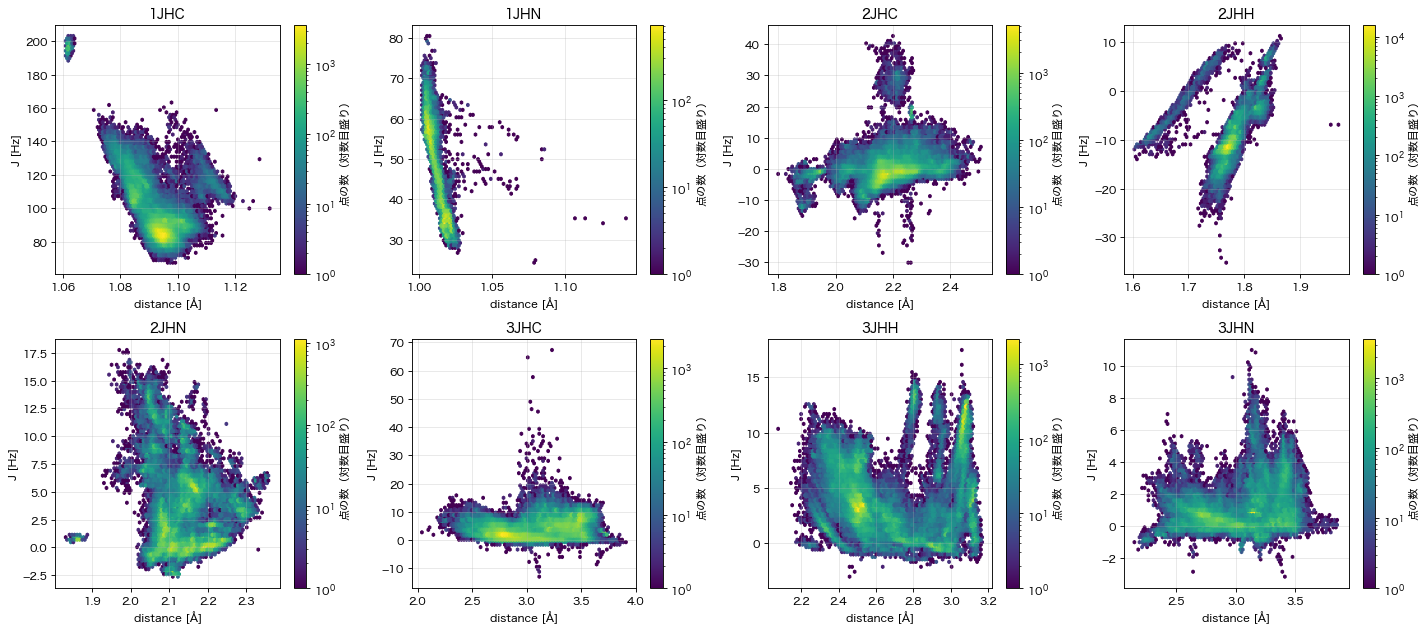

,1JHC,1JHN,2JHC,2JHH,2JHN,3JHC,3JHH,3JHN,score
距離（20ビン）,1.826,1.097,0.877,0.386,0.911,0.733,0.658,-0.184,0.788


In [10]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, t in zip(axes.flat, TYPES):
    d = BY_TYPE[t].sample(min(200000, len(BY_TYPE[t])), random_state=0)
    hb = ax.hexbin(d.dist, d.J, gridsize=80, bins='log', cmap='viridis', mincnt=1)
    plt.colorbar(hb, ax=ax, label='点の数（対数目盛り）')
    ax.set_title(t)
    ax.set_xlabel('distance [Å]')
    ax.set_ylabel('J [Hz]')
savefig('04_dist')
run('距離（20ビン）', {'*': [('dist', 20)]})

## 5. H1・H5: サブタイプ（結合数）と経路上の原子
- `deg1`: 結合相手 X の結合数（C なら混成）
- 1J: X の結合相手の元素構成（`nb_comp1`）。1位の「階層的な型埋め込み」に相当する情報
- 2J・3J: 中間原子 m1, m2 の元素と結合数

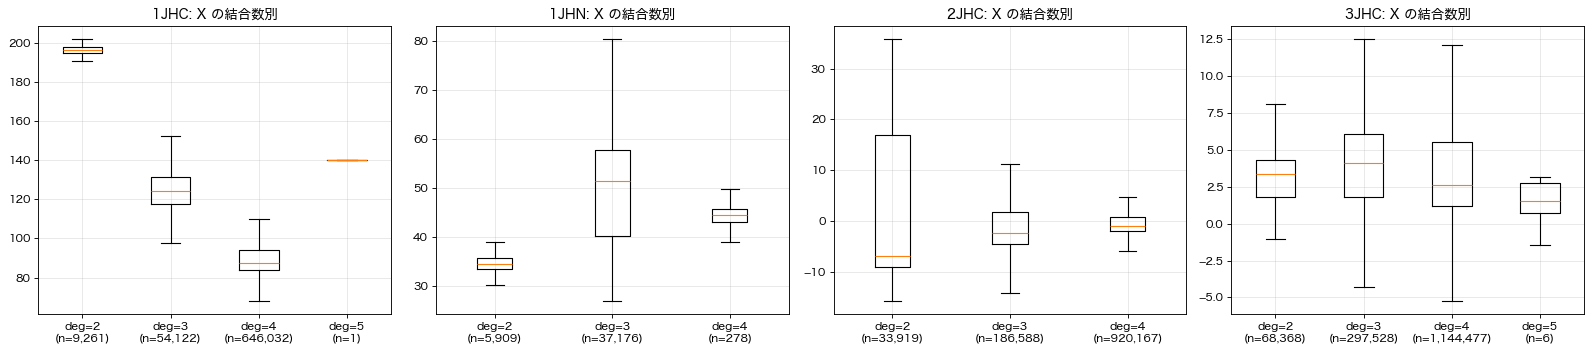

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, t in zip(axes, ['1JHC', '1JHN', '2JHC', '3JHC']):
    d = BY_TYPE[t]
    groups = sorted(d.deg1.unique())
    ax.boxplot([d.J[d.deg1 == k] for k in groups], tick_labels=[f'deg={k}\n(n={(d.deg1 == k).sum():,})' for k in groups],
               showfliers=False)
    ax.set_title(f'{t}: X の結合数別')
savefig('05_deg1')

In [12]:
def comp_label(code):
    cnt = []
    for e in reversed(ELEM):
        cnt.append(code % 5)
        code //= 5
    return ''.join(f'{e}{c}' for e, c in zip(ELEM, reversed(cnt)) if c)


def path_label(d, three):
    """中間原子を '元素+結合数' の文字列にする（3J は 'C4-C3' のように m1-m2）"""
    lab = pd.Series(ELEM[d.el_m1.clip(0).values], index=d.index) + d.deg_m1.astype(str)
    if three:
        el2 = pd.Series(np.where(d.el_m2.values >= 0, ELEM[d.el_m2.clip(0).values], '?'), index=d.index)
        lab = lab + '-' + el2 + d.deg_m2.astype(str)
    return lab


rows = []
for t in ['1JHC', '1JHN']:
    d = BY_TYPE[t]
    g = d.groupby('nb_comp1').J.agg(['size', 'median', 'std']).sort_values('size', ascending=False).head(8)
    g.index = [f'{t}: X の結合相手 = {comp_label(c)}' for c in g.index]
    rows.append(g)
pd.concat(rows)

,size,median,std
1JHC: X の結合相手 = H3C1,183798,84.3,2.939
1JHC: X の結合相手 = H2C2,179722,86.61,9.451
1JHC: X の結合相手 = H2C1O1,69078,90.9,7.759
1JHC: X の結合相手 = H1C3,55627,93,14.67
1JHC: X の結合相手 = H2C1N1,44770,93.31,11.34
1JHC: X の結合相手 = H1C2O1,43013,97.44,14.76
1JHC: X の結合相手 = H1C2N1,28606,106.6,14.68
1JHC: X の結合相手 = H1C2,23808,122.3,7.23
1JHN: X の結合相手 = H1C2,19286,49.41,11.33
1JHN: X の結合相手 = H2C1,15574,50.41,6.802


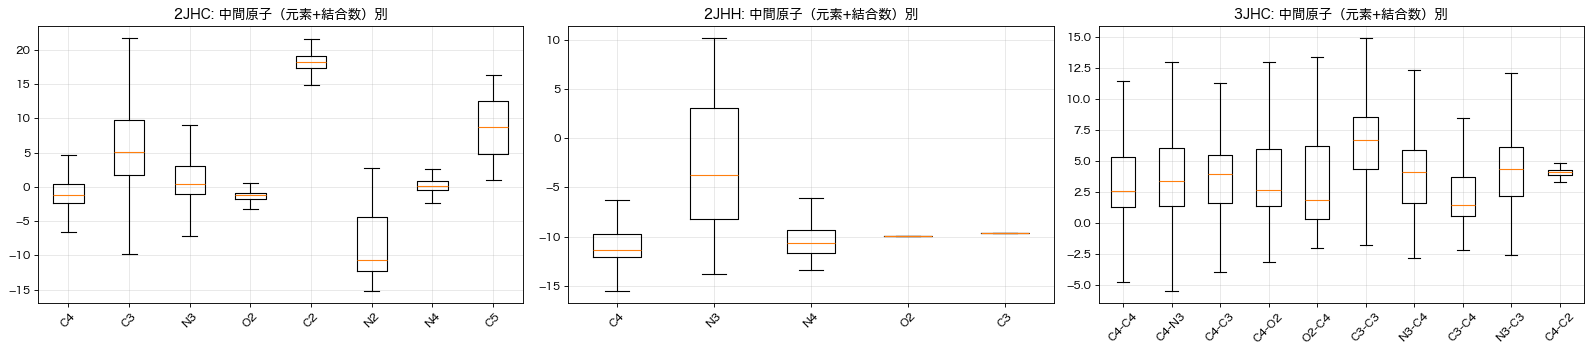

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
for ax, t in zip(axes, ['2JHC', '2JHH', '3JHC']):
    d = BY_TYPE[t]
    key = path_label(d, t.startswith('3'))
    top = key.value_counts().head(10).index
    ax.boxplot([d.J[key == k] for k in top], tick_labels=top, showfliers=False)
    ax.set_title(f'{t}: 中間原子（元素+結合数）別')
    ax.tick_params(axis='x', rotation=45)
savefig('05_path_atoms')

In [14]:
path_spec = {}
for t in TYPES:
    if t.startswith('1'):
        path_spec[t] = [('deg1', None), ('nb_comp1', None)]
    elif t.startswith('2'):
        path_spec[t] = [('el_m1', None), ('deg_m1', None), ('deg1', None)]
    else:
        path_spec[t] = [('el_m1', None), ('deg_m1', None), ('el_m2', None), ('deg_m2', None), ('deg1', None)]
run('X の結合数', {'*': [('deg1', None)]})
run('経路サブタイプ', path_spec)

,1JHC,1JHN,2JHC,2JHH,2JHN,3JHC,3JHH,3JHN,score
X の結合数,2.045,2.079,0.934,0.889,1.004,0.867,1.08,-0.106,1.099


,1JHC,1JHN,2JHC,2JHH,2JHN,3JHC,3JHH,3JHN,score
経路サブタイプ,1.866,1.973,0.685,0.86,0.725,0.795,1.058,-0.266,0.962


## 6. H3・H4: 2J の角度、3J の二面角

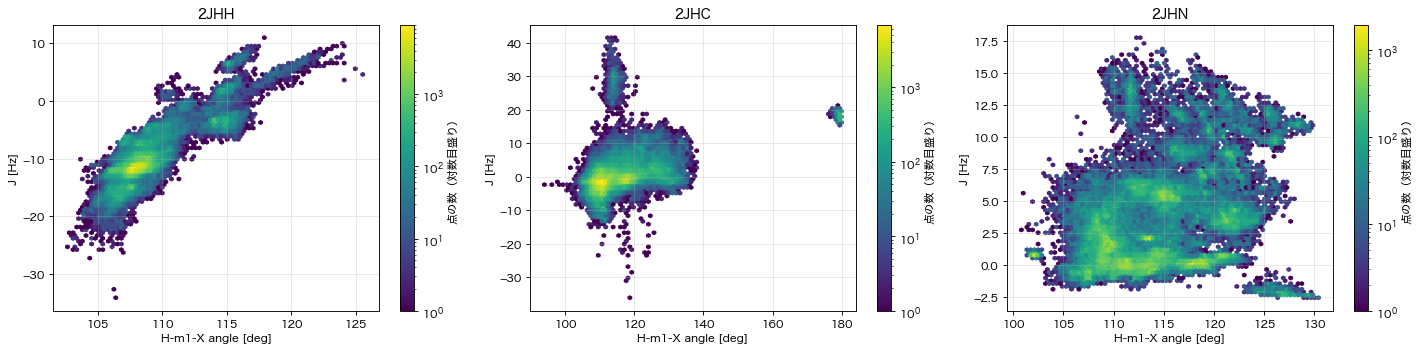

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, t in zip(axes, ['2JHH', '2JHC', '2JHN']):
    d = BY_TYPE[t].dropna(subset=['cos_angle']).sample(200000, random_state=0, replace=True)
    hb = ax.hexbin(np.degrees(np.arccos(d.cos_angle.clip(-1, 1))), d.J, gridsize=80, bins='log', cmap='viridis', mincnt=1)
    plt.colorbar(hb, ax=ax, label='点の数（対数目盛り）')
    ax.set_title(t)
    ax.set_xlabel('H-m1-X angle [deg]')
    ax.set_ylabel('J [Hz]')
savefig('06_angle')

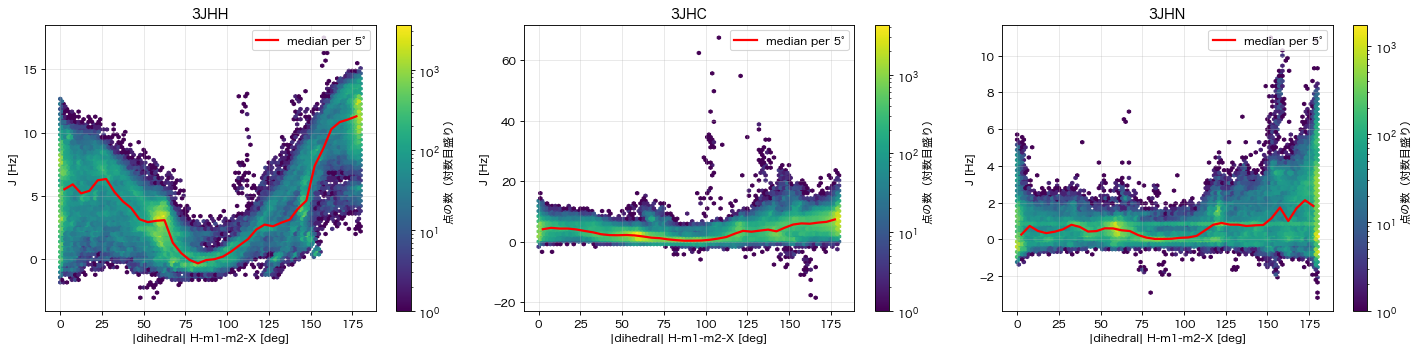

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, t in zip(axes, ['3JHH', '3JHC', '3JHN']):
    d = BY_TYPE[t].dropna(subset=['dihedral'])
    s = d.sample(min(300000, len(d)), random_state=0)
    hb = ax.hexbin(s.dihedral, s.J, gridsize=90, bins='log', cmap='viridis', mincnt=1)
    plt.colorbar(hb, ax=ax, label='点の数（対数目盛り）')
    b = (d.dihedral // 5) * 5 + 2.5
    med = d.groupby(b).J.median()
    ax.plot(med.index, med.values, color='red', lw=2, label='median per 5°')
    ax.set_title(t)
    ax.set_xlabel('|dihedral| H-m1-m2-X [deg]')
    ax.set_ylabel('J [Hz]')
    ax.legend()
savefig('06_dihedral')

In [17]:
geo_spec = {t: ([('cos_angle', 20)] if t.startswith('2') else [('dihedral', 18)] if t.startswith('3') else [('dist', 20)])
            for t in TYPES}
run('角度 / 二面角のみ（1J は距離）', geo_spec)
run('経路サブタイプ + 角度 / 二面角', {t: path_spec[t] + geo_spec[t] for t in TYPES})
run('経路サブタイプ + 角度 / 二面角 + 距離',
    {t: path_spec[t] + geo_spec[t] + ([] if t.startswith('1') else [('dist', 10)]) for t in TYPES})

,1JHC,1JHN,2JHC,2JHH,2JHN,3JHC,3JHH,3JHN,score
角度 / 二面角のみ（1J は距離）,1.826,1.097,0.83,0.371,0.937,0.48,0.375,-0.206,0.714


,1JHC,1JHN,2JHC,2JHH,2JHN,3JHC,3JHH,3JHN,score
経路サブタイプ + 角度 / 二面角,1.226,0.79,0.5,0.344,0.532,0.318,0.231,-0.613,0.416


,1JHC,1JHN,2JHC,2JHH,2JHN,3JHC,3JHH,3JHN,score
経路サブタイプ + 角度 / 二面角 + 距離,1.226,0.79,0.445,0.211,0.33,0.142,-0.157,-0.767,0.277


### 3JHH を中間原子の結合数で分けた Karplus 曲線
同じ二面角でも、中間の C─C が単結合同士（sp³-sp³）か二重結合（sp²-sp²）かで曲線が違うかを見る。

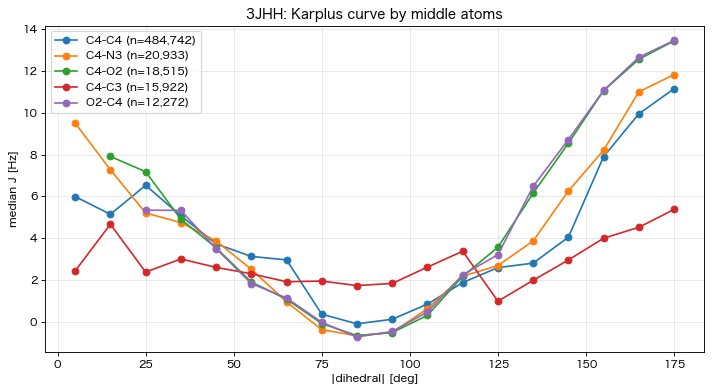

In [18]:
d = BY_TYPE['3JHH'].dropna(subset=['dihedral'])
key = path_label(d, True)
fig, ax = plt.subplots(figsize=(9, 5))
for k in key.value_counts().head(5).index:
    dd = d[key == k]
    med = dd.groupby((dd.dihedral // 10) * 10 + 5).J.median()
    ax.plot(med.index, med.values, marker='o', label=f'{k} (n={len(dd):,})')
ax.set_xlabel('|dihedral| [deg]')
ax.set_ylabel('median J [Hz]')
ax.set_title('3JHH: Karplus curve by middle atoms')
ax.legend()
savefig('06_karplus_by_path')

## 7. H6: 結合の種類（RDKit で一部の分子を確認）
距離だけで判定した結合（2章）と RDKit の `DetermineBonds`（xyz2mol）の結果を比べ、結合次数が J に効くかを見る。
時間がかかるので、train からランダムに 3,000 分子だけ処理する。

In [19]:
try:
    from rdkit import Chem, RDLogger
    from rdkit.Chem import rdDetermineBonds
    RDLogger.DisableLog('rdApp.*')
    HAS_RDKIT = True
except ImportError:
    HAS_RDKIT = False
    print('RDKit がないのでこの章はスキップ')

if HAS_RDKIT:
    sub_mols = RNG.choice(mol_tr, size=3000, replace=False)
    BO = {}
    t0 = time.time()
    n_fail = 0
    for mi in sub_mols:
        n = NA[mi]
        block = '\n'.join([str(n), ''] + [f'{ELEM[Z[mi, i]]} {x:.6f} {y:.6f} {z:.6f}' for i, (x, y, z) in enumerate(XYZ[mi, :n])])
        try:
            mol = Chem.MolFromXYZBlock(block)
            rdDetermineBonds.DetermineBonds(mol, charge=0)
        except Exception:
            n_fail += 1
            continue
        b = np.zeros((MAXA, MAXA), np.float32)
        for bond in mol.GetBonds():
            i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
            b[i, j] = b[j, i] = bond.GetBondTypeAsDouble()
        BO[mi] = b
    print(f'{len(BO)} 分子を処理（失敗 {n_fail}）: {time.time() - t0:.0f}s')
    agree = np.mean([((BO[mi] > 0) == A[mi]).all() for mi in BO])
    print('距離判定の結合と RDKit の結合が完全一致した分子の割合:', round(agree, 4))

2845 分子を処理（失敗 155）: 3s
距離判定の結合と RDKit の結合が完全一致した分子の割合: 0.9996


1JHC: X の結合数 × X の最大結合次数 ごとの J の中央値


median                        size             
x_max_bo    1     1.5   2     3         1   1.5  2   3  
deg1                                                    
2           NaN   NaN   NaN 196.1       NaN NaN  NaN 316
3         135.4 131.1 119.7   NaN         1 696 1159 NaN
4         87.12   NaN   NaN   NaN 2.142e+04 NaN  NaN NaN

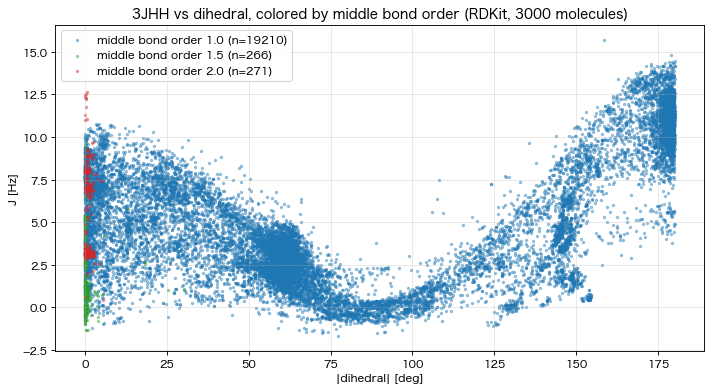

In [20]:
if HAS_RDKIT:
    sub = tr[tr.m.isin(list(BO))].copy()
    sm, s0, s1 = sub.m.values, sub.atom_index_0.values.astype(int), sub.atom_index_1.values.astype(int)
    # 1J: H─X の相手 X が持つ結合の最大次数（2 = 二重結合、3 = 三重結合、1.5 = 芳香族）
    sub['x_max_bo'] = [BO[a][x].max() for a, x in zip(sm, s1)]
    # 3J: 中間の m1─m2 結合の次数
    pos = tr.index.get_indexer(sub.index)
    sub['mid_bo'] = [BO[a][p, q] if q >= 0 else np.nan for a, p, q in zip(sm, m1[pos], m2[pos])]
    print('1JHC: X の結合数 × X の最大結合次数 ごとの J の中央値')
    s = sub[sub.type == '1JHC']
    display(s.pivot_table(index='deg1', columns='x_max_bo', values='J', aggfunc=['median', 'size']))

    fig, ax = plt.subplots(figsize=(9, 5))
    s = sub[(sub.type == '3JHH') & sub.dihedral.notna()]
    for bo, c in [(1.0, 'C0'), (1.5, 'C2'), (2.0, 'C3')]:
        dd = s[s.mid_bo == bo]
        ax.scatter(dd.dihedral, dd.J, s=4, alpha=0.4, color=c, label=f'middle bond order {bo} (n={len(dd)})')
    ax.set_xlabel('|dihedral| [deg]')
    ax.set_ylabel('J [Hz]')
    ax.set_title('3JHH vs dihedral, colored by middle bond order (RDKit, 3000 molecules)')
    ax.legend()
    savefig('07_bond_order_3jhh')

## 8. H7・H9: 電荷（Mulliken）と遮蔽（どちらも train にしかない）
「経路サブタイプ + 角度 / 二面角」で説明しきれない残りの誤差を、電荷や遮蔽がさらに説明するかを見る。
本物の値を使っているので、**test でも完璧に予測できた場合の上限**の効果になる。

In [21]:
best_geo = {t: path_spec[t] + geo_spec[t] for t in TYPES}
run('経路サブタイプ + 角度 / 二面角 + X の Mulliken', {t: best_geo[t] + [('mul1', 10)] for t in TYPES})
run('経路サブタイプ + 角度 / 二面角 + H の Mulliken', {t: best_geo[t] + [('mul0', 10)] for t in TYPES})
run('経路サブタイプ + 角度 / 二面角 + H の遮蔽', {t: best_geo[t] + [('shi0', 10)] for t in TYPES})
run('経路サブタイプ + 角度 / 二面角 + X の遮蔽', {t: best_geo[t] + [('shi1', 10)] for t in TYPES})

,1JHC,1JHN,2JHC,2JHH,2JHN,3JHC,3JHH,3JHN,score
経路サブタイプ + 角度 / 二面角 + X の Mulliken,1.126,0.616,0.433,0.076,0.278,0.273,0.176,-0.704,0.284


,1JHC,1JHN,2JHC,2JHH,2JHN,3JHC,3JHH,3JHN,score
経路サブタイプ + 角度 / 二面角 + H の Mulliken,1.029,0.462,0.43,0.065,0.329,0.268,0.162,-0.668,0.26


,1JHC,1JHN,2JHC,2JHH,2JHN,3JHC,3JHH,3JHN,score
経路サブタイプ + 角度 / 二面角 + H の遮蔽,1.1,0.422,0.424,0.104,0.322,0.234,0.102,-0.713,0.249


,1JHC,1JHN,2JHC,2JHH,2JHN,3JHC,3JHH,3JHN,score
経路サブタイプ + 角度 / 二面角 + X の遮蔽,1.136,0.603,0.461,0.119,0.349,0.289,0.124,-0.662,0.302


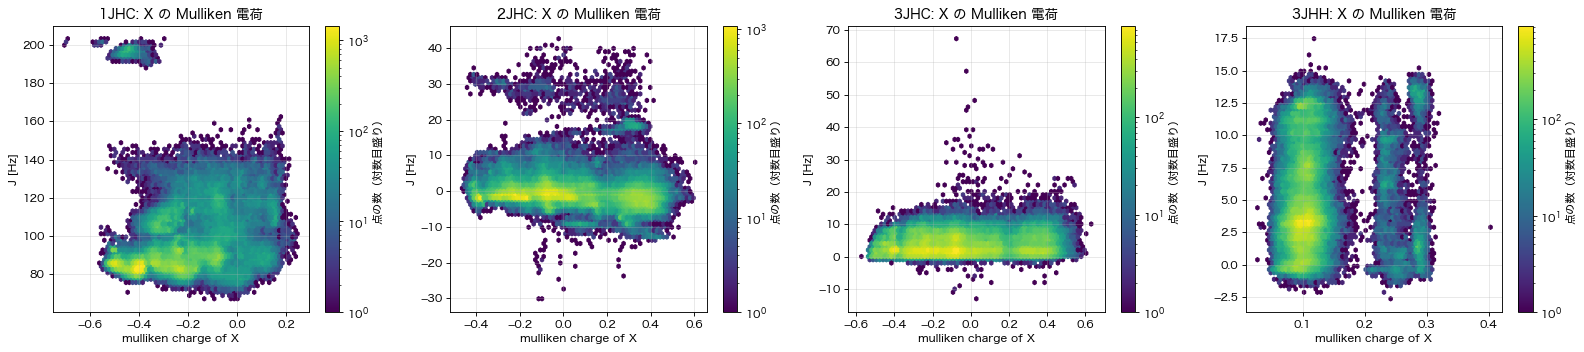

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, t in zip(axes, ['1JHC', '2JHC', '3JHC', '3JHH']):
    d = BY_TYPE[t].sample(150000, random_state=0)
    hb = ax.hexbin(d.mul1, d.J, gridsize=70, bins='log', cmap='viridis', mincnt=1)
    plt.colorbar(hb, ax=ax, label='点の数（対数目盛り）')
    ax.set_title(f'{t}: X の Mulliken 電荷')
    ax.set_xlabel('mulliken charge of X')
    ax.set_ylabel('J [Hz]')
savefig('08_mulliken')

## 9. H8: 補助ターゲット（fc / sd / pso / dso）

In [23]:
comp_rows = []
for t in TYPES:
    d = BY_TYPE[t]
    comp_rows.append({
        'type': t,
        'std(J)': d.J.std(),
        **{f'std({c})': d[c].std() for c in ['fc', 'sd', 'pso', 'dso']},
        'corr(fc, J)': np.corrcoef(d.fc, d.J)[0, 1],
        'std(J - fc)': (d.J - d.fc).std(),
    })
pd.DataFrame(comp_rows).set_index('type')

,std(J),std(fc),std(sd),std(pso),std(dso),"corr(fc, J)",std(J - fc)
type,,,,,,,
1JHC,18.28,18.42,0.1273,0.4608,0.1957,0.9999,0.3312
1JHN,10.92,10.86,0.05587,0.2377,0.05058,0.9997,0.2529
2JHC,4.524,4.45,0.1091,0.553,0.186,0.9919,0.5772
2JHH,3.98,4.05,0.03767,0.473,0.5131,0.9996,0.1353
2JHN,3.673,3.832,0.03569,0.2452,0.04799,0.9983,0.2682
3JHC,3.071,3.109,0.0417,0.1932,0.2654,0.9994,0.1103
3JHH,3.705,3.864,0.06343,0.8272,1.185,0.995,0.4099
3JHN,1.315,1.313,0.02456,0.1033,0.08298,0.9971,0.1004


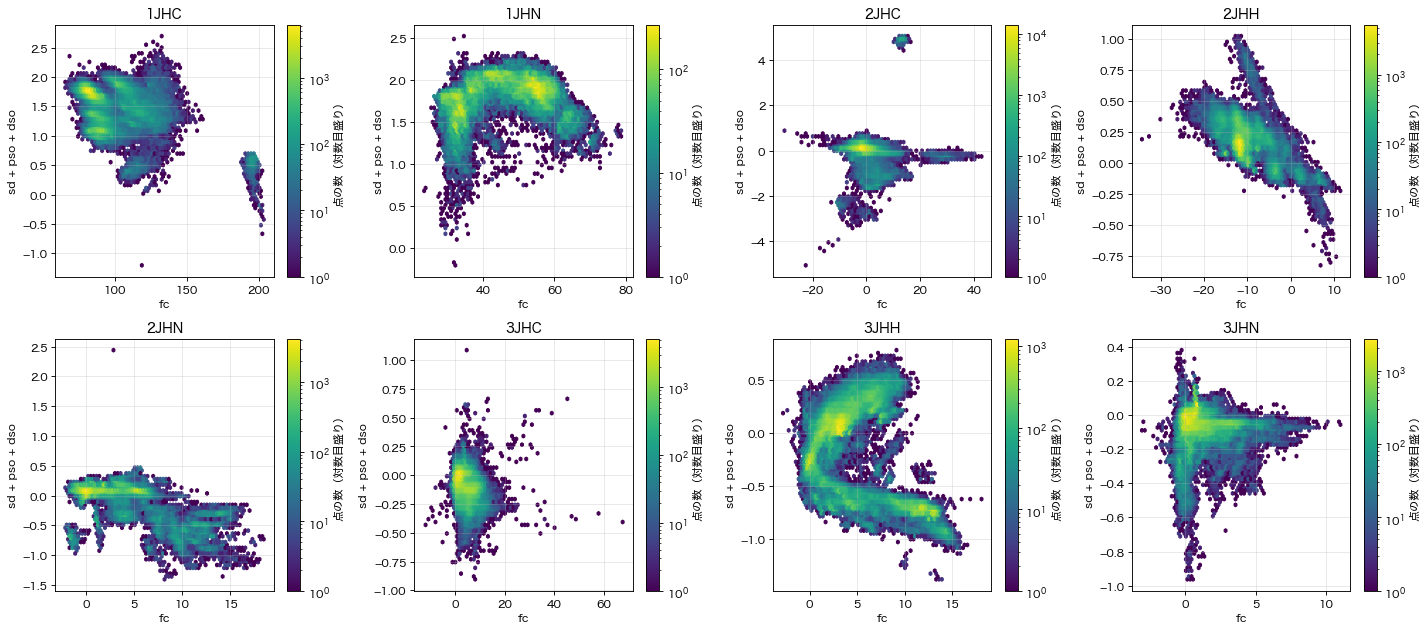

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, t in zip(axes.flat, TYPES):
    d = BY_TYPE[t].sample(min(150000, len(BY_TYPE[t])), random_state=0)
    hb = ax.hexbin(d.fc, d.J - d.fc, gridsize=70, bins='log', cmap='viridis', mincnt=1)
    plt.colorbar(hb, ax=ax, label='点の数（対数目盛り）')
    ax.set_title(t)
    ax.set_xlabel('fc')
    ax.set_ylabel('sd + pso + dso')
savefig('09_contrib')

## 10. H10: 対称性
- HH ペアは片方向だけ載っている（2位・7位は入れ替えた行を追加し、予測を平均した）
- 3J で H─m1─m2─X の経路が複数ある（環の中など）場合、二面角が1つに決まらない（7位は経路ごとに行を複製して平均した）

In [25]:
hh = tr[tr.type.isin(['2JHH', '3JHH'])]
print('HH ペアで atom_index_0 < atom_index_1 の割合:', round((hh.atom_index_0 < hh.atom_index_1).mean(), 4))
print('3J の経路数の分布:')
display(tr[tr.type.astype(str).str.startswith('3')].groupby('type', observed=True).npath.value_counts(normalize=True)
        .unstack().round(4))

HH ペアで atom_index_0 < atom_index_1 の割合: 1.0
3J の経路数の分布:


npath,0,1,2,3
type,,,,
3JHC,0,0.9051,0.0909,0.004
3JHH,0,1,NaN,NaN
3JHN,0,0.937,0.0613,0.0017


## 11. まとめ: 各要素でどこまで J を説明できるか
値は検証用 20% の分子での log(MAE)（低いほど良い）。`score` は8 type の平均（＝コンペの指標）。

,1JHC,1JHN,2JHC,2JHH,2JHN,3JHC,3JHH,3JHN,score
type のみ,2.427,2.285,0.961,0.889,1.058,0.884,1.080,-0.094,1.186
距離（20ビン）,1.826,1.097,0.877,0.386,0.911,0.733,0.658,-0.184,0.788
X の結合数,2.045,2.079,0.934,0.889,1.004,0.867,1.080,-0.106,1.099
経路サブタイプ,1.866,1.973,0.685,0.860,0.725,0.795,1.058,-0.266,0.962
角度 / 二面角のみ（1J は距離）,1.826,1.097,0.830,0.371,0.937,0.480,0.375,-0.206,0.714
経路サブタイプ + 角度 / 二面角,1.226,0.790,0.500,0.344,0.532,0.318,0.231,-0.613,0.416
経路サブタイプ + 角度 / 二面角 + 距離,1.226,0.790,0.445,0.211,0.330,0.142,-0.157,-0.767,0.277
経路サブタイプ + 角度 / 二面角 + X の Mulliken,1.126,0.616,0.433,0.076,0.278,0.273,0.176,-0.704,0.284
経路サブタイプ + 角度 / 二面角 + H の Mulliken,1.029,0.462,0.430,0.065,0.329,0.268,0.162,-0.668,0.260
経路サブタイプ + 角度 / 二面角 + H の遮蔽,1.100,0.422,0.424,0.104,0.322,0.234,0.102,-0.713,0.249


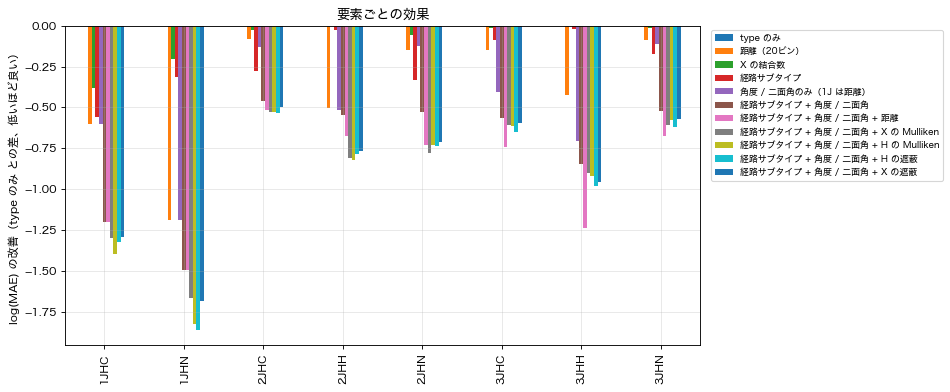

In [26]:
res = pd.DataFrame(RESULTS).T[TYPES + ['score']]
res.to_csv(FIG / '11_summary.csv')
display(res.style.background_gradient(cmap='RdYlGn_r', axis=0).format('{:.3f}'))

fig, ax = plt.subplots(figsize=(12, 5))
(res[TYPES] - res.loc['type のみ', TYPES]).T.plot.bar(ax=ax)
ax.set_ylabel('log(MAE) の改善（type のみ との差、低いほど良い）')
ax.set_title('要素ごとの効果')
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
savefig('11_summary')